# Import the libraries


1.   numpy
2.   pandas
3.   pyplot from matplotlib
4.   seaborn





In [1]:
# Import libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Print library versions
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

# Set random seed
np.random.seed(1)

NumPy version: 2.1.3
Pandas version: 2.2.3


In [ ]:
# Evaluation cell, Skip it ...

# Exercise 1 (03 points)

The spam table of §4.2 is S = np.array([[10, 4], [2, 1], [7, 3], [1, 2]]) (links, words in
subject), weights Θ = (0.3, 0.7), bias 0.5.
1. Compute z = S @ np.array([0.3, 0.7]) + 0.5 and check that the first value is 6.3 as in the lecture.
2. Apply the sigmoid 1 / (1 + np.exp(-z)) to the whole vector. Which e-mails are predicted as spam
(probability ≥ 0.5)?

In [2]:
# Write your code here

S = np.array([[10,4],[2,1],[7,3],[1,2]])
theta = np.array([0.3,0.7])
bias =0.5

# 1. Compute linear combination z
z = S @ theta + bias

# 2. Compute sigmoid probabilities and predict spam (probability >= 0.5)
probabilities = 1 / (1 + np.exp(-z))

# Identify predicted spam emails
predicted_spam =  probabilities >= 0.5

In [ ]:
# Auto-graded cell (S)
# Skip it

In [ ]:
# Auto-graded cell (theta)
# Skip it

In [ ]:
# Auto-graded cell (bias)
# Skip it

In [ ]:
# Auto-graded cell (z)
# Skip it

In [ ]:
# Auto-graded cell (probabilities)
# Skip it

In [ ]:
# Auto-graded cell predicted_spam
# Skip it

# Exercise 2 (05 points)
Let's create a log of 300 login events with a few missing values and a few suspicious bursts of failed attempts.

In [3]:
# Create the log of 300 login events with a few missing values and a few suspicious bursts of failed attempts.
rng = np.random.default_rng(1)
n = 300
log = pd.DataFrame({"user":    rng.choice(["ali", "sara", "yacine", "nour", "karim"], n),
                    "hour":    rng.integers(0, 24, n),
                    "failed_attempts": rng.poisson(0.4, n),
                    "country": rng.choice(["DZ", "FR", "TN", "RU"], n, p=[.7, .15, .1, .05]),
                    "duration_min": rng.gamma(2, 8, n).round(1)})

In [ ]:
# Auto graded cell (log)
# skip it

In [4]:
# Choose 12 random indexes
idx = rng.choice(n, 12, replace=False)

# Generate 12 random values between 5 and 10
values = rng.integers(5, 11, 12)

# Update failed attempts
log.loc[idx, "failed_attempts"] = values

In [ ]:
# Autograded cell (Failed attempts)
# Skip it

In [5]:
# Insert 10 missing values randomly
missing_idx = rng.choice(n, 10, replace=False)

log.loc[missing_idx, "duration_min"] = np.nan
# Calculate the median
median = log["duration_min"].median()

# Replace missing values with the median
log["duration_min"] = log["duration_min"].fillna(median)

# Create the night column
log["night"] = (log["hour"] < 6).astype(int)

print(log.isna().sum())
print(log[["hour", "night", "duration_min"]].head())

user               0
hour               0
failed_attempts    0
country            0
duration_min       0
night              0
dtype: int64
   hour  night  duration_min
0     2      1          24.0
1    23      0          23.2
2    11      0           4.8
3     9      0           4.2
4    17      0          21.8


In [ ]:
# Auto graded cell (missing values)
# skip it

1. How many logins come from Russia (RU) with at least 5 failed attempts?

In [6]:

# Filter Russian logins with at least 5 failed attempts

ru_log_at_least_five_attempts = log[
    (log["country"] == "RU") &
    (log["failed_attempts"] >= 5)
]

print(ru_log_at_least_five_attempts)

print(
    "Number of logins:",
    len(ru_log_at_least_five_attempts)
)

   user  hour  failed_attempts country  duration_min  night
46  ali    15                9      RU           6.5      0
Number of logins: 1


In [ ]:
# Auto-graded cell (ru_log_at_least_five_attempts)
# Skip it

2. Which user has the highest total number of failed attempts? (groupby + sum + sort_values)

In [7]:
# Group by user and calculate total failed attempts

user_max_failed_attempts = (
    log.groupby("user")["failed_attempts"]
    .sum()
    .sort_values(ascending=False)
)

print(user_max_failed_attempts)

user
karim     51
nour      45
ali       44
yacine    43
sara      36
Name: failed_attempts, dtype: int64


In [ ]:
# Auto-graded cell user_max_failed_attemps)
# Skip it

3. Add a column long_session equal to 1 when duration_min is above 30.

In [8]:
# Create long_session column

log["long_session"] = (
    log["duration_min"] > 30
).astype(int)

print(log.head())

     user  hour  failed_attempts country  duration_min  night  long_session
0  yacine     2                0      DZ          24.0      1             0
1  yacine    23                0      FR          23.2      0             0
2    nour    11                0      FR           4.8      0             0
3   karim     9                0      DZ           4.2      0             0
4     ali    17                0      DZ          21.8      0             0


In [ ]:
# Autograded cell - Skip it

# Exercise 3 (03 points)
1. Draw the histogram of failed_attempts.
2. Why is a histogram better than the mean (0.7) to describe this column?
3. Then draw a bar chart of the mean failed_attempts per night value.

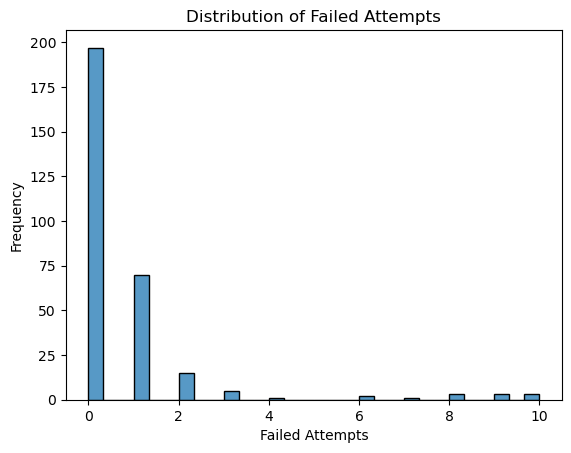

In [9]:
# Draw histogram

sns.histplot(
    data=log,
    x="failed_attempts",
    bins=30
)

plt.title("Distribution of Failed Attempts")
plt.xlabel("Failed Attempts")
plt.ylabel("Frequency")

plt.show()

In [ ]:
# Auto-graded cell - Skip it...

In [ ]:
2. Why is a histogram better than the mean (0.7) to describe this column?
    A: The mean is too difficult to calculate.
    B: The distribution is highly skewed with zero-inflation and rare extreme bursts.
    C: Histograms only work with categorical data.
    D: The mean cannot be calculated for numeric values.

In [ ]:
# Write your code here
answer_q2 ="B"

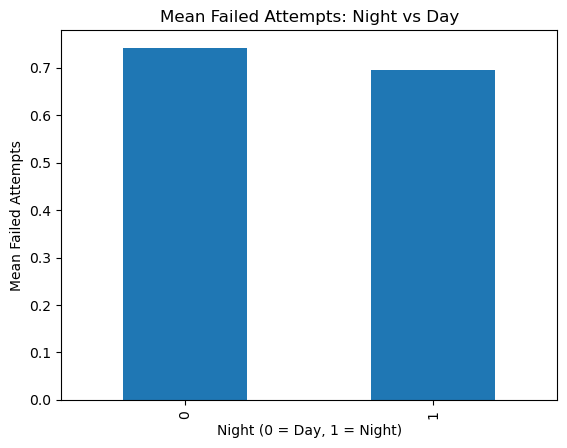

In [10]:
# Calculate mean failed attempts per night
night_mean = log.groupby("night")["failed_attempts"].mean()

# Draw bar chart
night_mean.plot.bar()

plt.title("Mean Failed Attempts: Night vs Day")
plt.xlabel("Night (0 = Day, 1 = Night)")
plt.ylabel("Mean Failed Attempts")

plt.show()

In [ ]:
# Auttograded cell - Skip it

Q1. If (300, 4) is the shape of a numpy array X.
What does X[:, 2] return? (01 point)

In [ ]:
answer_q1 = "X[:, 2] returns all rows from the third column."

Q2. Give the Pandas command that shows the number of missing values in each column of a given df. (01 point)

In [11]:
df = log

df.isna().sum()

user               0
hour               0
failed_attempts    0
country            0
duration_min       0
night              0
long_session       0
dtype: int64

Q3. Which plot would you use to see whether logins from RU have more failed attempts than logins from DZ? (01 point)

In [ ]:
answer_q3 = "Box plot"

Q4. Why do we scale features before training a model (one sentence)? (01 point)

In [ ]:
answer_q4 = "To put all features on the same scale so that no feature dominates the others."

Commit the logins_clean.csv.(0.5 point)

In [12]:
# Save cleaned data
log.to_csv("logins_clean.csv", index=False)

print("File saved successfully!")

File saved successfully!


In [ ]:
# Autograded cell - Skip it

# Bonus (02 points)
On logins_clean.csv, build the matrix X with the columns hour, failed_attempts,
duration_min, night using df[cols].to_numpy(), scale it as in Cell 1.5, and print its shape. This is exactly the input Workshop 2 will feed to Scikit-learn.

In [13]:
# Load the cleaned CSV file
df = pd.read_csv("logins_clean.csv")

# Select the required columns
cols = [
    "hour",
    "failed_attempts",
    "duration_min",
    "night"
]

# Convert DataFrame to NumPy array
X = df[cols].to_numpy()

# Apply feature scaling
X_scaled = (X - X.mean(axis=0)) / X.std(axis=0)

# Print results
print("Original shape:", X.shape)

print("Scaled matrix:")
print(X_scaled.round(2))

print("Scaled shape:", X_scaled.shape)

print("Mean:", X_scaled.mean(axis=0).round(6))

print("Standard deviation:", X_scaled.std(axis=0))

Original shape: (300, 4)
Scaled matrix:
[[-1.32 -0.42  0.79  1.67]
 [ 1.62 -0.42  0.71 -0.6 ]
 [-0.06 -0.42 -0.95 -0.6 ]
 ...
 [-1.46 -0.42 -0.93  1.67]
 [ 0.5   0.74  4.12 -0.6 ]
 [-1.18  0.16 -0.73  1.67]]
Scaled shape: (300, 4)
Mean: [ 0. -0.  0.  0.]
Standard deviation: [1. 1. 1. 1.]


In [ ]:
import numpy as np
import pandas as pd
